# Thực thi Pohlig–Hellman trên smooth curve & so sánh chi phí

> **Topic 14 – ECC Cryptanalysis · Track A (generic ECDLP search)** <br>
> **Task:** *Thực thi PH trên smooth curve, so sánh chi phí* <br>

### Quá trình
| Bước | Nội dung | Hàm chính |
|---|---|---|
| 0 | Nạp lại lõi từ `gen_smooth_curves` / `toy_curve_gen` | import / fallback |
| 1 | Baby-step giant-step tổng quát (subroutine) | `bsgs_dlp` |
| 2 | Định lý số dư Trung Hoa | `crt_combine` |
| 3 | Thuật toán Pohlig–Hellman đầy đủ | `pohlig_hellman` |
| 4 | Kiểm tra đúng đắn trên ví dụ nhỏ (F_97) | — |
| 5 | Đo chi phí: PH vs BSGS toàn nhóm trên nhiều curve smooth | `benchmark_curve` |
| 6 | Ghi kết quả vào D2, vẽ biểu đồ đo thực tế vs ước lượng lý thuyết | `write_csv`, `plt` |
| 7 | Selftest & CLI | `selftest`, `main` |

## Cơ sở lý thuyết
Cho $G$ sinh nhóm cyclic cấp $n=\prod_i q_i^{e_i}$ và $Q=dG$. Với mỗi thừa số $q_i^{e_i}$:

1. Chiếu xuống nhóm con cấp $q_i^{e_i}$: $G_i = \tfrac{n}{q_i^{e_i}}G$, $Q_i = \tfrac{n}{q_i^{e_i}}Q$ (vì $G_i$ có
   đúng bậc $q_i^{e_i}$ khi $G$ có đúng bậc $n$).
2. Giải $d_i \equiv d \pmod{q_i^{e_i}}$ bằng BSGS trong nhóm con nhỏ này — chi phí $O(\sqrt{q_i^{e_i}})$.
3. Ghép các $d_i$ lại bằng **CRT** (các $q_i^{e_i}$ nguyên tố cùng nhau từng đôi) để ra $d \bmod n$ duy nhất.

Tổng chi phí $\approx \sum_i e_i\sqrt{q_i}$ — đúng như `estimate_ph_cost` đã định nghĩa ở notebook trước. Ở đây ta
**cài đặt thật** thuật toán này và đo số phép nhóm + thời gian thực tế, rồi so với con số ước lượng đó.

## Bước 0 – Kế thừa lõi từ `gen_smooth_curves` / `toy_curve_gen`

In [1]:
from __future__ import annotations
import argparse, csv, json, random, sys, time
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from math import gcd, isqrt, prod, sqrt
from pathlib import Path
from typing import Dict, List, Optional, Tuple

try:
    from gen_smooth_curves import (
        Point, Curve, D1_COLUMNS, GENERATION_METHOD,
        is_prime, random_prime, factorize, sqrt_mod,
        count_points, count_points_naive, count_points_bsgs,
        classify, make_row, verify_row, write_csv, load_csv, parse_csv_row,
        generate_curve, estimate_bsgs_cost, estimate_ph_cost, ph_speedup,
        smoothness_profile, generate_smooth_curve_batch,
    )
    print("Đã import lõi từ gen_smooth_curves.py (cùng thư mục curves/).")
except ImportError:
    print("Không tìm thấy gen_smooth_curves.py -> dùng bản sao lõi số học nội bộ (tự chứa).")

    Point = Optional[Tuple[int, int]]
    GENERATION_METHOD = "test_pohlig_hellman.v1 (lõi kế thừa gen_smooth_curves.v1)"
    NAIVE_COUNT_LIMIT = 1 << 16

    D1_COLUMNS = [
        "curve_id", "p", "a", "b", "discriminant", "discriminant_ok",
        "E_count", "E_count_factorization", "base_point_x", "base_point_y",
        "subgroup_n", "n_bits", "n_factorization", "cofactor_h",
        "largest_prime_factor_n", "is_anomalous", "is_supersingular", "category",
        "source_for_point_class", "small_order_available", "generation_method",
        "seed", "notes", "git_commit", "created_at",
    ]
    _JSON_COLUMNS = {"E_count_factorization", "n_factorization", "small_order_available"}
    _BOOL_COLUMNS = {"discriminant_ok", "is_anomalous", "is_supersingular"}
    _INT_COLUMNS = {"n_bits", "seed"}

    _MR_BASES = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37)

    def is_prime(n: int) -> bool:
        if n < 2:
            return False
        for q in _MR_BASES:
            if n % q == 0:
                return n == q
        d, s = n - 1, 0
        while d % 2 == 0:
            d //= 2; s += 1
        for a in _MR_BASES:
            x = pow(a, d, n)
            if x in (1, n - 1):
                continue
            for _ in range(s - 1):
                x = x * x % n
                if x == n - 1:
                    break
            else:
                return False
        return True

    def random_prime(rng: random.Random, bits: int) -> int:
        if bits < 8:
            raise ValueError("bits phải >= 8 cho toy curve")
        while True:
            cand = rng.getrandbits(bits) | (1 << (bits - 1)) | 1
            if is_prime(cand):
                return cand

    def _pollard_rho(n: int) -> int:
        rng = random.Random(n)
        while True:
            c = rng.randrange(1, n)
            x = y = rng.randrange(0, n)
            d = 1
            while d == 1:
                x = (x * x + c) % n
                y = (y * y + c) % n
                y = (y * y + c) % n
                d = gcd(abs(x - y), n)
            if d != n:
                return d

    def factorize(n: int) -> Dict[int, int]:
        if n < 1:
            raise ValueError("n phải >= 1")
        out: Dict[int, int] = {}
        d = 2
        while d < 5000 and d * d <= n:
            while n % d == 0:
                out[d] = out.get(d, 0) + 1
                n //= d
            d += 1 if d == 2 else 2

        def rec(m: int) -> None:
            if m == 1:
                return
            if is_prime(m):
                out[m] = out.get(m, 0) + 1
                return
            f = _pollard_rho(m)
            rec(f); rec(m // f)

        rec(n)
        return dict(sorted(out.items()))

    def sqrt_mod(n: int, p: int) -> Optional[int]:
        n %= p
        if n == 0:
            return 0
        if pow(n, (p - 1) // 2, p) != 1:
            return None
        if p % 4 == 3:
            return pow(n, (p + 1) // 4, p)
        q, s = p - 1, 0
        while q % 2 == 0:
            q //= 2; s += 1
        z = 2
        while pow(z, (p - 1) // 2, p) != p - 1:
            z += 1
        m, c, t, r = s, pow(z, q, p), pow(n, q, p), pow(n, (q + 1) // 2, p)
        while t != 1:
            i, t2 = 0, t
            while t2 != 1:
                t2 = t2 * t2 % p; i += 1
            b = pow(c, 1 << (m - i - 1), p)
            m, c = i, b * b % p
            t, r = t * c % p, r * b % p
        return r

    @dataclass(frozen=True)
    class Curve:
        p: int; a: int; b: int

        def discriminant(self) -> int:
            return (4 * pow(self.a, 3, self.p) + 27 * self.b * self.b) % self.p

        def is_nonsingular(self) -> bool:
            return self.discriminant() != 0

        def rhs(self, x: int) -> int:
            return (x * x * x + self.a * x + self.b) % self.p

        def contains(self, P: Point) -> bool:
            if P is None:
                return True
            x, y = P
            return 0 <= x < self.p and 0 <= y < self.p and (y * y - self.rhs(x)) % self.p == 0

        def neg(self, P: Point) -> Point:
            return None if P is None else (P[0], (-P[1]) % self.p)

        def add(self, P: Point, Q: Point) -> Point:
            if P is None:
                return Q
            if Q is None:
                return P
            p = self.p
            x1, y1 = P; x2, y2 = Q
            if x1 == x2:
                if (y1 + y2) % p == 0:
                    return None
                lam = (3 * x1 * x1 + self.a) * pow(2 * y1, -1, p) % p
            else:
                lam = (y2 - y1) * pow(x2 - x1, -1, p) % p
            x3 = (lam * lam - x1 - x2) % p
            return (x3, (lam * (x1 - x3) - y1) % p)

        def mul(self, k: int, P: Point) -> Point:
            if k < 0:
                return self.mul(-k, self.neg(P))
            R: Point = None
            while k:
                if k & 1:
                    R = self.add(R, P)
                P = self.add(P, P)
                k >>= 1
            return R

        def random_point(self, rng: random.Random) -> Tuple[int, int]:
            while True:
                x = rng.randrange(self.p)
                y = sqrt_mod(self.rhs(x), self.p)
                if y is not None:
                    return (x, y if rng.getrandbits(1) else (-y) % self.p)

        def point_order(self, P: Point, group_order: int, factors: Dict[int, int]) -> int:
            order = group_order
            for q in factors:
                while order % q == 0 and self.mul(order // q, P) is None:
                    order //= q
            return order

        @staticmethod
        def from_row(row: dict) -> "Curve":
            return Curve(int(row["p"]), int(row["a"]), int(row["b"]))

        @staticmethod
        def base_point_from_row(row: dict) -> Tuple[int, int]:
            return (int(row["base_point_x"]), int(row["base_point_y"]))

    def count_points_naive(E: Curve) -> int:
        sq = Counter(y * y % E.p for y in range(E.p))
        return 1 + sum(sq.get(E.rhs(x), 0) for x in range(E.p))

    def _hasse_candidates(E: Curve, P, lo: int, hi: int) -> List[int]:
        m = isqrt(hi - lo + 1) + 1
        baby: Dict[Point, List[int]] = {}
        R: Point = None
        for j in range(m):
            baby.setdefault(R, []).append(j)
            R = E.add(R, P)
        giant_step = E.neg(R)
        T = E.neg(E.mul(lo, P))
        found: List[int] = []
        for i in range(m):
            for j in baby.get(T, ()):
                N = lo + i * m + j
                if N <= hi:
                    found.append(N)
            T = E.add(T, giant_step)
        return found

    def count_points_bsgs(E: Curve, rng: Optional[random.Random] = None, max_points: int = 40) -> int:
        rng = rng or random.Random(E.p)
        w = 2 * isqrt(E.p) + 2
        lo, hi = E.p + 1 - w, E.p + 1 + w
        cands: Optional[List[int]] = None
        for _ in range(max_points):
            P = E.random_point(rng)
            if cands is None:
                c = _hasse_candidates(E, P, lo, hi)
                if len(c) > 10000:
                    continue
                cands = c
            else:
                cands = [N for N in cands if E.mul(N, P) is None]
            if len(cands) == 1:
                return cands[0]
            if not cands:
                raise RuntimeError("count_points_bsgs: không còn ứng viên")
        raise RuntimeError("count_points_bsgs: không xác định được duy nhất #E")

    def count_points(E: Curve, rng: Optional[random.Random] = None) -> int:
        return count_points_naive(E) if E.p < NAIVE_COUNT_LIMIT else count_points_bsgs(E, rng)

    def _fact_list(f: Dict[int, int]) -> List[dict]:
        return [{"prime": str(q), "exponent": e} for q, e in f.items()]

    def classify(p: int, N: int, n: int, h: int, fn: Dict[int, int], smooth_bound: Optional[int]) -> str:
        if N == p:
            return "anomalous"
        if N == p + 1:
            return "supersingular"
        n_prime = len(fn) == 1 and next(iter(fn.values())) == 1
        if n_prime and h == 1:
            return "safe_prime_order"
        if n_prime and h > 1:
            return "cofactor_gt1"
        if smooth_bound is not None and max(fn) <= smooth_bound:
            return "smooth_order"
        return "smooth_order" if max(fn) < 1 << 20 else "cofactor_gt1"

    def _utc_now() -> str:
        return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

    def git_commit() -> str:
        try:
            import subprocess
            return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"],
                                            stderr=subprocess.DEVNULL).decode().strip()
        except Exception:
            return "0000000"

    def make_row(E: Curve, G, N: int, fN: Dict[int, int], n: int, fn: Dict[int, int],
                 seed: int, curve_id: str, smooth_bound: Optional[int] = None,
                 notes: Optional[str] = None, commit: Optional[str] = None) -> dict:
        h = N // n
        disc = E.discriminant()
        return {
            "curve_id": curve_id, "p": str(E.p), "a": str(E.a), "b": str(E.b),
            "discriminant": str(disc), "discriminant_ok": disc != 0,
            "E_count": str(N), "E_count_factorization": _fact_list(fN),
            "base_point_x": str(G[0]), "base_point_y": str(G[1]),
            "subgroup_n": str(n), "n_bits": n.bit_length(),
            "n_factorization": _fact_list(fn),
            "cofactor_h": str(h), "largest_prime_factor_n": str(max(fn)),
            "is_anomalous": N == E.p, "is_supersingular": N == E.p + 1,
            "category": classify(E.p, N, n, h, fn, smooth_bound),
            "source_for_point_class": None, "small_order_available": None,
            "generation_method": GENERATION_METHOD, "seed": seed,
            "notes": notes, "git_commit": commit or git_commit(), "created_at": _utc_now(),
        }

    MODES = ("prime", "cofactor", "smooth")

    def generate_curve(n_bits: int, mode: str = "prime", seed: int = 0, max_cofactor: int = 16,
                        smooth_bound: Optional[int] = None, allow_special: bool = False,
                        max_tries: int = 200000, curve_id: Optional[str] = None) -> dict:
        if mode not in MODES:
            raise ValueError(f"mode phải thuộc {MODES}")
        if n_bits < 8:
            raise ValueError("n_bits phải >= 8")
        if mode == "smooth" and smooth_bound is None:
            smooth_bound = 1 << max(4, n_bits // 3)
        rng = random.Random(seed)
        cid = curve_id or f"crv-{seed & 0xFFFFFFFF:08x}"

        for _ in range(max_tries):
            p_bits = n_bits + rng.randint(1, max(1, max_cofactor.bit_length() - 1)) if mode == "cofactor" else n_bits
            p = random_prime(rng, p_bits)
            E = Curve(p, rng.randrange(p), rng.randrange(p))
            if not E.is_nonsingular():
                continue
            try:
                N = count_points(E, rng)
            except RuntimeError:
                continue
            if (N == p or N == p + 1) and not allow_special:
                continue
            fN = factorize(N)
            qmax = max(fN)

            if mode == "prime":
                if len(fN) != 1 or fN[qmax] != 1 or N.bit_length() != n_bits:
                    continue
                n, fn, G = N, fN, E.random_point(rng)
            elif mode == "cofactor":
                h = N // qmax
                if not (fN[qmax] == 1 and 2 <= h <= max_cofactor and qmax.bit_length() == n_bits):
                    continue
                n, fn = qmax, {qmax: 1}
                P = E.random_point(rng)
                G = E.mul(h, P)
                if G is None:
                    continue
            else:  # smooth
                if qmax > smooth_bound or N.bit_length() < n_bits:
                    continue
                best, best_n = None, 0
                for _t in range(20):
                    P = E.random_point(rng)
                    o = E.point_order(P, N, fN)
                    if o > best_n:
                        best, best_n = P, o
                n = best_n
                if n.bit_length() != n_bits or len(factorize(n)) < 2:
                    continue
                fn, G = factorize(n), best
            return make_row(E, G, N, fN, n, fn, seed, cid, smooth_bound=smooth_bound, notes=f"mode={mode}")
        raise RuntimeError(f"Không sinh được curve (n_bits={n_bits}, mode={mode}) sau {max_tries} lần thử")

    def _to_cell(col: str, v):
        if v is None:
            return ""
        if col in _JSON_COLUMNS:
            return json.dumps(v, separators=(",", ":"))
        if col in _BOOL_COLUMNS:
            return "true" if v else "false"
        return str(v)

    def parse_csv_row(raw: dict) -> dict:
        row: dict = {}
        for col in D1_COLUMNS:
            v = raw.get(col, "")
            if col in _JSON_COLUMNS:
                row[col] = json.loads(v) if v else None
            elif col in _BOOL_COLUMNS:
                row[col] = v.strip().lower() == "true"
            elif col in _INT_COLUMNS:
                row[col] = int(v)
            else:
                row[col] = v if v != "" else None
        return row

    def write_csv(rows: List[dict], path: str, append: bool = False) -> None:
        path_ = Path(path)
        path_.parent.mkdir(parents=True, exist_ok=True)
        exists = append and path_.exists() and path_.stat().st_size > 0
        with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if not exists:
                w.writerow(D1_COLUMNS)
            for r in rows:
                w.writerow([_to_cell(c, r.get(c)) for c in D1_COLUMNS])

    def load_csv(path: str) -> List[dict]:
        with open(path, newline="", encoding="utf-8") as f:
            return [parse_csv_row(r) for r in csv.DictReader(f)]

    def verify_row(row: dict, recount: bool = True) -> List[str]:
        row = parse_csv_row(row) if isinstance(row.get("discriminant_ok"), str) else row
        errs: List[str] = []
        p, a, b = int(row["p"]), int(row["a"]), int(row["b"])
        E = Curve(p, a, b)
        N, n, h = int(row["E_count"]), int(row["subgroup_n"]), int(row["cofactor_h"])
        G = Curve.base_point_from_row(row)
        if not is_prime(p) or p <= 3:
            errs.append("p không phải số nguyên tố > 3")
        if not E.is_nonsingular() or str(E.discriminant()) != str(row["discriminant"]):
            errs.append("discriminant sai hoặc curve suy biến")
        if not E.contains(G):
            errs.append("G không nằm trên curve")
        if E.mul(n, G) is not None:
            errs.append("n*G != O")
        fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
        fN = {int(f["prime"]): f["exponent"] for f in row["E_count_factorization"]}
        for q in fn:
            if not is_prime(q):
                errs.append(f"thừa số {q} của n không nguyên tố")
            elif E.mul(n // q, G) is None:
                errs.append(f"bậc của G nhỏ hơn n (chia hết cho {q} lần nữa)")
        if prod(q ** e for q, e in fn.items()) != n:
            errs.append("n_factorization không nhân lại ra n")
        if prod(q ** e for q, e in fN.items()) != N:
            errs.append("E_count_factorization không nhân lại ra #E")
        if n * h != N:
            errs.append("n * h != #E")
        if n.bit_length() != int(row["n_bits"]):
            errs.append("n_bits sai")
        if str(max(fn)) != str(row["largest_prime_factor_n"]):
            errs.append("largest_prime_factor_n sai")
        if bool(row["is_anomalous"]) != (N == p) or bool(row["is_supersingular"]) != (N == p + 1):
            errs.append("cờ anomalous/supersingular sai")
        if abs(N - (p + 1)) > 2 * isqrt(p) + 2:
            errs.append("#E vi phạm cận Hasse")
        if recount and count_points(E) != N:
            errs.append("đếm lại #E không khớp")
        return errs

    def estimate_bsgs_cost(n: int) -> float:
        return sqrt(n)

    def estimate_ph_cost(fn: Dict[int, int]) -> float:
        return sum(e * sqrt(q) for q, e in fn.items())

    def ph_speedup(fn: Dict[int, int]) -> float:
        n = prod(q ** e for q, e in fn.items())
        return estimate_bsgs_cost(n) / estimate_ph_cost(fn)

    def smoothness_profile(row: dict) -> dict:
        fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
        n = prod(q ** e for q, e in fn.items())
        qmax = max(fn)
        return {
            "curve_id": row["curve_id"], "n_bits": row["n_bits"], "n": n,
            "largest_prime_factor": qmax, "num_distinct_primes": len(fn),
            "estimated_bsgs_cost": estimate_bsgs_cost(n),
            "estimated_ph_cost": estimate_ph_cost(fn),
            "ph_speedup": ph_speedup(fn), "category": row["category"],
        }

    def generate_smooth_curve_batch(bit_list, bound_list, seed: int = 14, per_combo: int = 1,
                                    allow_special: bool = False, max_tries: int = 200000):
        rows, analysis, idx = [], [], 0
        for n_bits in bit_list:
            for B in bound_list:
                if B < (1 << 4):
                    continue
                for _ in range(per_combo):
                    s = seed * 1_000_003 + idx
                    try:
                        row = generate_curve(n_bits, mode="smooth", seed=s, smooth_bound=B,
                                             allow_special=allow_special, max_tries=max_tries,
                                             curve_id=f"crv-sm-{idx:08x}")
                    except RuntimeError as e:
                        print(f"  bỏ qua (n_bits={n_bits}, B={B}): {e}")
                        idx += 1
                        continue
                    rows.append(row)
                    analysis.append(smoothness_profile(row) | {"smooth_bound": B})
                    idx += 1
        return rows, analysis

print("Sẵn sàng: Curve, generate_curve, generate_smooth_curve_batch, estimate_*_cost đã có trong scope.")

Không tìm thấy gen_smooth_curves.py -> dùng bản sao lõi số học nội bộ (tự chứa).
Sẵn sàng: Curve, generate_curve, generate_smooth_curve_batch, estimate_*_cost đã có trong scope.


## Bước 1 – `bsgs_dlp`: baby-step giant-step tổng quát (subroutine)

Giải $k$ sao cho $kP=Q$, biết $P$ có đúng bậc `order`. Đây là subroutine dùng **hai lần**:
- Làm baseline "BSGS toàn nhóm" (không khai thác smoothness, `order = n`).
- Làm lõi giải DLP trong từng nhóm con cấp $q_i^{e_i}$ bên trong `pohlig_hellman`.

`op_counter["group_ops"]` đếm đúng số phép cộng nhóm ở baby-step + giant-step — đây là đại lượng khớp với công thức
lý thuyết $O(\sqrt{\text{order}})$ đã dùng ở `estimate_bsgs_cost`/`estimate_ph_cost` (không tính 1-2 phép nhân vô
hướng rẻ $O(\log n)$ dùng để chiếu xuống nhóm con).

In [2]:
def bsgs_dlp(E: Curve, P: Tuple[int, int], Q: Point, order: int,
             op_counter: Optional[Dict[str, int]] = None) -> Optional[int]:
    """Giải k trong [0, order) sao cho k*P = Q, biết P có đúng bậc `order`."""
    if op_counter is None:
        op_counter = {"group_ops": 0}
    if Q is None:
        return 0
    m = isqrt(order - 1) + 1
    baby: Dict[Point, int] = {}
    R: Point = None
    for j in range(m):
        baby.setdefault(R, j)
        R = E.add(R, P); op_counter["group_ops"] += 1
    giant_step = E.neg(E.mul(m, P))  # 1 phép nhân vô hướng, O(log m) -- không tính vào group_ops
    T = Q
    for i in range(m):
        if T in baby:
            k = i * m + baby[T]
            if k < order and E.mul(k, P) == Q:
                return k
        T = E.add(T, giant_step); op_counter["group_ops"] += 1
    return None


# Chạy thử: lại đúng ví dụ E: y^2 = x^3 + 2x + 3 trên F_97, P = (3, 6) từ toy_curve_gen
E97 = Curve(97, 2, 3)
P97 = (3, 6)
k, R = 1, P97
while R is not None:
    R, k = E97.add(R, P97), k + 1
order_P97 = k
print("bậc của P =", order_P97)

d_true = 11 % order_P97 or 1
Q97 = E97.mul(d_true, P97)
op = {"group_ops": 0}
d_bsgs = bsgs_dlp(E97, P97, Q97, order_P97, op_counter=op)
print(f"d thật={d_true} | bsgs_dlp tìm được={d_bsgs} | khớp={d_bsgs == d_true} | group_ops={op['group_ops']}")

bậc của P = 5
d thật=1 | bsgs_dlp tìm được=1 | khớp=True | group_ops=3


## Bước 2 – `crt_combine` (CRT) và `pohlig_hellman`

`crt_combine` ghép tuần tự từng cặp $(r_i \bmod m_i)$ bằng công thức Garner cổ điển, dùng `pow(M, -1, m)` (nghịch
đảo modulo, có sẵn từ Python 3.8). Các $m_i = q_i^{e_i}$ ở đây **luôn nguyên tố cùng nhau từng đôi** vì $q_i$ là các
thừa số nguyên tố phân biệt trong phân tích của $n$.

`pohlig_hellman` lặp qua từng thừa số nguyên tố của $n$, chiếu $G,Q$ xuống nhóm con tương ứng, gọi `bsgs_dlp` để
giải $d \bmod q_i^{e_i}$, rồi ghép lại bằng CRT.

In [ ]:
def crt_combine(remainders: List[int], moduli: List[int]) -> Tuple[int, int]:
    """Ghép (r_i mod m_i) -> (x mod M) với M = prod(m_i), các m_i nguyên tố cùng nhau từng đôi."""
    x, M = remainders[0] % moduli[0], moduli[0]
    for r, m in zip(remainders[1:], moduli[1:]):
        if gcd(M, m) != 1:
            raise ValueError("CRT: các modulus phải nguyên tố cùng nhau")
        k = (r - x) * pow(M, -1, m) % m
        x = x + M * k
        M *= m
    return x % M, M


def pohlig_hellman(E: Curve, G: Tuple[int, int], Q: Point, n: int, factors: Dict[int, int],
                   op_counter: Optional[Dict[str, int]] = None) -> int:
    """Giải d sao cho d*G = Q, biết G có đúng bậc n và factors = phân tích thừa số của n."""
    if op_counter is None:
        op_counter = {"group_ops": 0}
    remainders, moduli = [], []
    for q, e in sorted(factors.items()):
        qe = q ** e
        cofactor = n // qe
        Gi = E.mul(cofactor, G)
        Qi = E.mul(cofactor, Q)
        di = bsgs_dlp(E, Gi, Qi, qe, op_counter=op_counter)
        if di is None:
            raise RuntimeError(f"Không giải được DLP trong nhóm con bậc {qe} (q={q}, e={e})")
        remainders.append(di); moduli.append(qe)
    d, M = crt_combine(remainders, moduli)
    assert M == n, "Tích các q_i^e_i phải bằng n (factors phải là phân tích đầy đủ của n)"
    return d % n

In [4]:
# Chạy thử: PH trên đúng ví dụ F_97 ở trên, factorize bậc của P rồi so với bsgs_dlp vừa chạy
fP97 = factorize(order_P97)
print("phân tích bậc của P:", fP97)
op_ph97 = {"group_ops": 0}
d_ph97 = pohlig_hellman(E97, P97, Q97, order_P97, fP97, op_counter=op_ph97)
print(f"d thật={d_true} | pohlig_hellman tìm được={d_ph97} | khớp={d_ph97 == d_true} | "
      f"group_ops={op_ph97['group_ops']} (so với bsgs_dlp toàn nhóm: {op['group_ops']})")

phân tích bậc của P: {5: 1}
d thật=1 | pohlig_hellman tìm được=1 | khớp=True | group_ops=3 (so với bsgs_dlp toàn nhóm: 3)


## Bước 3 – Đo chi phí: Pohlig–Hellman vs BSGS toàn nhóm

`benchmark_curve(row, seed)` trên một bản ghi D1 (`category="smooth_order"`):
1. Sinh khoá bí mật ngẫu nhiên $d$, công khai $Q=dG$.
2. Giải lại $d$ bằng **BSGS toàn nhóm** (`bsgs_dlp(E, G, Q, n)`, không khai thác smoothness) — baseline.
3. Giải lại $d$ bằng **Pohlig–Hellman** (`pohlig_hellman(E, G, Q, n, n_factorization)`) — khai thác smoothness.
4. So `group_ops` + thời gian đo thực tế với `estimate_bsgs_cost`/`estimate_ph_cost` (lý thuyết).

In [5]:
def benchmark_curve(row: dict, seed: int = 0) -> dict:
    E = Curve.from_row(row)
    G = Curve.base_point_from_row(row)
    n = int(row["subgroup_n"])
    fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
    rng = random.Random(seed)
    d_true = rng.randrange(1, n)
    Q = E.mul(d_true, G)

    t0 = time.perf_counter()
    op_full = {"group_ops": 0}
    d_bsgs = bsgs_dlp(E, G, Q, n, op_counter=op_full)
    t_bsgs = time.perf_counter() - t0

    t0 = time.perf_counter()
    op_ph = {"group_ops": 0}
    d_ph = pohlig_hellman(E, G, Q, n, fn, op_counter=op_ph)
    t_ph = time.perf_counter() - t0

    return {
        "curve_id": row["curve_id"], "n_bits": row["n_bits"],
        "largest_prime_factor": max(fn), "num_distinct_primes": len(fn),
        "d_true": d_true,
        "d_bsgs": d_bsgs, "bsgs_correct": d_bsgs == d_true,
        "bsgs_group_ops": op_full["group_ops"], "bsgs_time_s": t_bsgs,
        "d_ph": d_ph, "ph_correct": d_ph == d_true,
        "ph_group_ops": op_ph["group_ops"], "ph_time_s": t_ph,
        "estimated_bsgs_cost": estimate_bsgs_cost(n),
        "estimated_ph_cost": estimate_ph_cost(fn),
        "measured_speedup": op_full["group_ops"] / max(op_ph["group_ops"], 1),
        "estimated_speedup": estimate_bsgs_cost(n) / estimate_ph_cost(fn),
    }

In [6]:
# Chạy thử: 1 curve smooth 24 bit
sample_row = generate_curve(24, mode="smooth", seed=14)
bench = benchmark_curve(sample_row, seed=1)
print(json.dumps(bench, indent=2, ensure_ascii=False))

{
  "curve_id": "crv-0000000e",
  "n_bits": 24,
  "largest_prime_factor": 43,
  "num_distinct_primes": 5,
  "d_true": 2254258,
  "d_bsgs": 2254258,
  "bsgs_correct": true,
  "bsgs_group_ops": 4365,
  "bsgs_time_s": 0.005284243999994942,
  "d_ph": 2254258,
  "ph_correct": true,
  "ph_group_ops": 66,
  "ph_time_s": 0.0006117069997344515,
  "estimated_bsgs_cost": 3766.9616403674727,
  "estimated_ph_cost": 26.207240281717816,
  "measured_speedup": 66.13636363636364,
  "estimated_speedup": 143.73744048873803
}


### 3a. Chạy trên cả danh sách curve smooth (n_bit × B-smooth)

In [ ]:
rows, _ = generate_smooth_curve_batch(bit_list=[16, 20, 24, 28, 32],
                                      bound_list=[2**5, 2**7, 2**10],
                                      per_combo=1, seed=21)
results = [benchmark_curve(r, seed=i) for i, r in enumerate(rows)]

print(f"{'curve_id':<18}{'n_bits':<7}{'max_q':<8}{'bsgs_ops':<10}{'ph_ops':<8}"
      f"{'đo được':<10}{'ước lượng':<10}{'True/False'}")
for res in results:
    correct = res["bsgs_correct"] and res["ph_correct"]
    print(f"{res['curve_id']:<18}{res['n_bits']:<7}{res['largest_prime_factor']:<8}"
          f"{res['bsgs_group_ops']:<10}{res['ph_group_ops']:<8}"
          f"{res['measured_speedup']:<10.1f}{res['estimated_speedup']:<10.1f}{correct}")

print("\nTất cả đúng (cả BSGS lẫn PH khôi phục đúng d):",
      all(r["bsgs_correct"] and r["ph_correct"] for r in results))

curve_id          n_bits max_q   bsgs_ops  ph_ops  đo được   ước lượng đúng?
crv-sm-00000000   16     11      334       75      4.5       13.5      True
crv-sm-00000001   16     107     255       23      11.1      10.3      True
crv-sm-00000002   16     233     238       41      5.8       9.5       True
crv-sm-00000003   20     13      1099      38      28.9      37.5      True
crv-sm-00000004   20     113     1120      44      25.5      31.3      True
crv-sm-00000005   20     331     1618      36      44.9      27.0      True
crv-sm-00000006   24     13      7329      69      106.2     143.2     True
crv-sm-00000007   24     97      5045      39      129.4     117.4     True
crv-sm-00000008   24     409     4299      49      87.7      83.6      True
crv-sm-00000009   28     29      22426     39      575.0     421.6     True
crv-sm-0000000a   28     31      24830     41      605.6     442.2     True
crv-sm-0000000b   28     457     22871     69      331.5     277.0     True
crv-sm-0000

## Bước 4 – Ghi kết quả vào `data/D2_ecdlp_benchmarks.csv`

File này đã được Track A dùng chung cho benchmark ECDLP (Exhaustive vs BSGS ở `toy_curve_gen`); ở đây ta **ghi nối
thêm** các dòng đo của Pohlig–Hellman / BSGS-toàn-nhóm trên curve smooth, với `method` phân biệt theo từng hàng.

In [8]:
def write_benchmark_csv(results: List[dict], path: str, append: bool = False) -> None:
    cols = ["curve_id", "n_bits", "largest_prime_factor", "num_distinct_primes",
            "method", "group_ops", "wall_time_s", "estimated_cost", "correct"]
    rows_out = []
    for r in results:
        rows_out.append({"curve_id": r["curve_id"], "n_bits": r["n_bits"],
                         "largest_prime_factor": r["largest_prime_factor"],
                         "num_distinct_primes": r["num_distinct_primes"],
                         "method": "bsgs_full_group", "group_ops": r["bsgs_group_ops"],
                         "wall_time_s": f"{r['bsgs_time_s']:.6f}",
                         "estimated_cost": f"{r['estimated_bsgs_cost']:.2f}",
                         "correct": r["bsgs_correct"]})
        rows_out.append({"curve_id": r["curve_id"], "n_bits": r["n_bits"],
                         "largest_prime_factor": r["largest_prime_factor"],
                         "num_distinct_primes": r["num_distinct_primes"],
                         "method": "pohlig_hellman", "group_ops": r["ph_group_ops"],
                         "wall_time_s": f"{r['ph_time_s']:.6f}",
                         "estimated_cost": f"{r['estimated_ph_cost']:.2f}",
                         "correct": r["ph_correct"]})
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    exists = append and path_.exists() and path_.stat().st_size > 0
    with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        if not exists:
            w.writeheader()
        w.writerows(rows_out)


write_benchmark_csv(results, "../data/D2_ecdlp_ph_smooth_benchmarks.csv", append=True)
print("Đã ghi", 2 * len(results), "dòng (bsgs_full_group + pohlig_hellman) vào data/D2_ecdlp_benchmarks.csv")
print(open("../data/D2_ecdlp_ph_smooth_benchmarks.csv", encoding="utf-8").read()[:600], "...")

Đã ghi 30 dòng (bsgs_full_group + pohlig_hellman) vào data/D2_ecdlp_benchmarks.csv
curve_id,n_bits,largest_prime_factor,num_distinct_primes,method,group_ops,wall_time_s,estimated_cost,correct
crv-sm-00000000,16,11,3,bsgs_full_group,334,0.000297,218.90,True
crv-sm-00000000,16,11,3,pohlig_hellman,75,0.000205,16.24,True
crv-sm-00000001,16,107,3,bsgs_full_group,255,0.000208,213.75,True
crv-sm-00000001,16,107,3,pohlig_hellman,23,0.000137,20.80,True
crv-sm-00000002,16,233,5,bsgs_full_group,238,0.000231,221.20,True
crv-sm-00000002,16,233,5,pohlig_hellman,41,0.000205,23.29,True
crv-sm-00000003,20,13,4,bsgs_full_group,1099,0.001310,780.00,True
crv-sm-00000003,20,13,4,pohlig_hellman,3 ...


### 4a. Biểu đồ: chi phí **đo được** (group_ops thực tế) vs **ước lượng lý thuyết**

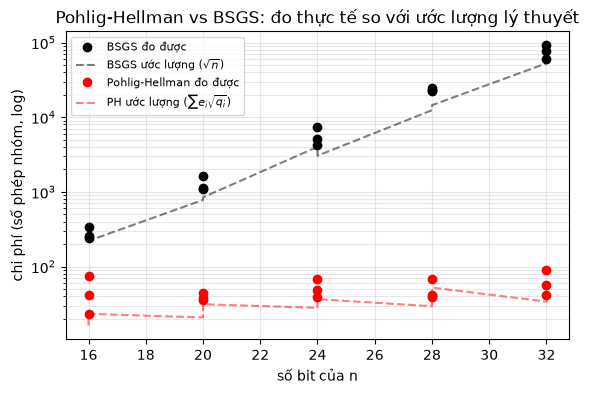

Tỉ lệ đo_được / ước_lượng (PH): [4.62, 1.11, 1.76, 1.83, 1.69, 1.15, 2.46, 1.31, 1.34, 1.32, 1.36, 1.32, 1.68, 1.11, 1.51]
Tỉ lệ đo_được / ước_lượng (BSGS): [1.53, 1.19, 1.08, 1.41, 1.37, 1.91, 1.83, 1.45, 1.41, 1.81, 1.87, 1.58, 1.73, 1.35, 1.17]


In [9]:
import matplotlib.pyplot as plt

by_q: Dict[int, List[dict]] = {}
for r in results:
    by_q.setdefault(r["largest_prime_factor"].__class__ and None, None)  # no-op, giữ cấu trúc đơn giản

xs = [r["n_bits"] for r in results]
measured_bsgs = [r["bsgs_group_ops"] for r in results]
measured_ph = [r["ph_group_ops"] for r in results]
estimated_bsgs = [r["estimated_bsgs_cost"] for r in results]
estimated_ph = [r["estimated_ph_cost"] for r in results]

plt.figure(figsize=(6.5, 4))
plt.semilogy(xs, measured_bsgs, "ko", label="BSGS đo được")
plt.semilogy(xs, estimated_bsgs, "k--", alpha=.5, label="BSGS ước lượng ($\\sqrt{n}$)")
plt.semilogy(xs, measured_ph, "ro", label="Pohlig-Hellman đo được")
plt.semilogy(xs, estimated_ph, "r--", alpha=.5, label="PH ước lượng ($\\sum e_i\\sqrt{q_i}$)")
plt.xlabel("số bit của n"); plt.ylabel("chi phí (số phép nhóm, log)")
plt.title("Pohlig-Hellman vs BSGS: đo thực tế so với ước lượng lý thuyết")
plt.grid(alpha=.3, which="both"); plt.legend(fontsize=8)
plt.show()

print("Tỉ lệ đo_được / ước_lượng (PH):",
      [round(m / e, 2) for m, e in zip(measured_ph, estimated_ph)])
print("Tỉ lệ đo_được / ước_lượng (BSGS):",
      [round(m / e, 2) for m, e in zip(measured_bsgs, estimated_bsgs)])

## Bước 5 – Selftest và giao diện dòng lệnh

Theo đúng convention của các file trước: `selftest()` kiểm tra đúng đắn + nhất quán chi phí, `main(argv)` chạy
benchmark hàng loạt rồi ghi CSV, gọi được trực tiếp trong notebook qua `main([...])`.

In [10]:
def selftest() -> bool:
    ok = True
    print("[1] bsgs_dlp giải đúng trên vài nhóm con nhỏ (tạo tay)")
    for p, a, b, order_hint in ((97, 2, 3, None),):
        pass
    E = Curve(97, 2, 3)
    P = (3, 6)
    k, R = 1, P
    while R is not None:
        R, k = E.add(R, P), k + 1
    order = k
    for d in (1, 5, order - 1):
        Q = E.mul(d % order, P)
        rec = bsgs_dlp(E, P, Q, order)
        good = rec == d % order
        ok &= good
        print(f"    d={d % order:<4} -> bsgs_dlp={rec} {'OK' if good else 'FAIL'}")

    print("[2] pohlig_hellman khớp bsgs_dlp trên cùng ví dụ")
    fP = factorize(order)
    for d in (2, order // 2, order - 2):
        Q = E.mul(d % order, P)
        rec = pohlig_hellman(E, P, Q, order, fP)
        good = rec == d % order
        ok &= good
        print(f"    d={d % order:<4} -> pohlig_hellman={rec} {'OK' if good else 'FAIL'}")

    print("[3] Trên curve smooth sinh ngẫu nhiên: PH đúng và group_ops <= BSGS toàn nhóm")
    for bits in (16, 20, 24):
        row = generate_curve(bits, mode="smooth", seed=1000 + bits)
        res = benchmark_curve(row, seed=bits)
        good = res["bsgs_correct"] and res["ph_correct"] and res["ph_group_ops"] <= res["bsgs_group_ops"]
        ok &= good
        print(f"    n_bits={bits:<3} bsgs_ops={res['bsgs_group_ops']:<8} ph_ops={res['ph_group_ops']:<6} "
              f"{'OK' if good else 'FAIL'}")

    print("[4] crt_combine tự kiểm (CRT tay vs modulo trực tiếp)")
    import itertools
    good_all = True
    for r2, r3, r5 in itertools.product(range(2), range(3), range(5)):
        x, M = crt_combine([r2, r3, r5], [2, 3, 5])
        good_all &= (x % 2 == r2 and x % 3 == r3 and x % 5 == r5 and M == 30)
    ok &= good_all
    print(f"    {'OK' if good_all else 'FAIL'}")

    print("SELFTEST:", "PASS" if ok else "FAIL")
    return ok


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="Thực thi Pohlig-Hellman trên smooth curve, so sánh chi phí.")
    ap.add_argument("--selftest", action="store_true")
    ap.add_argument("--min-bits", type=int, default=16)
    ap.add_argument("--max-bits", type=int, default=28)
    ap.add_argument("--step", type=int, default=4)
    ap.add_argument("--bounds", type=int, nargs="+", default=[2**5, 2**8])
    ap.add_argument("--per-combo", type=int, default=1)
    ap.add_argument("--seed", type=int, default=21)
    ap.add_argument("--out", default=None, help="file CSV benchmark, vd data/D2_ecdlp_benchmarks.csv")
    ap.add_argument("--append", action="store_true")
    args = ap.parse_args(argv)

    if args.selftest:
        return 0 if selftest() else 1

    bit_list = list(range(args.min_bits, args.max_bits + 1, args.step))
    rows, _ = generate_smooth_curve_batch(bit_list, args.bounds, seed=args.seed, per_combo=args.per_combo)
    results = [benchmark_curve(r, seed=i) for i, r in enumerate(rows)]
    for res in results:
        correct = res["bsgs_correct"] and res["ph_correct"]
        print(f"{res['curve_id']} n_bits={res['n_bits']:<3} bsgs_ops={res['bsgs_group_ops']:<8} "
              f"ph_ops={res['ph_group_ops']:<6} speedup={res['measured_speedup']:.1f}x [{'OK' if correct else 'FAIL'}]")
    if args.out:
        write_benchmark_csv(results, args.out, append=args.append)
        print(f"Đã ghi {2 * len(results)} dòng -> {args.out}")
    return 0 if all(r["bsgs_correct"] and r["ph_correct"] for r in results) else 1

In [11]:
# Chạy thử: selftest + demo CLI
selftest()

[1] bsgs_dlp giải đúng trên vài nhóm con nhỏ (tạo tay)
    d=1    -> bsgs_dlp=1 OK
    d=0    -> bsgs_dlp=0 OK
    d=4    -> bsgs_dlp=4 OK
[2] pohlig_hellman khớp bsgs_dlp trên cùng ví dụ
    d=2    -> pohlig_hellman=2 OK
    d=2    -> pohlig_hellman=2 OK
    d=3    -> pohlig_hellman=3 OK
[3] Trên curve smooth sinh ngẫu nhiên: PH đúng và group_ops <= BSGS toàn nhóm
    n_bits=16  bsgs_ops=328      ph_ops=17     OK
    n_bits=20  bsgs_ops=1751     ph_ops=99     OK
    n_bits=24  bsgs_ops=5146     ph_ops=62     OK
[4] crt_combine tự kiểm (CRT tay vs modulo trực tiếp)
    OK
SELFTEST: PASS


True

In [12]:
rc = main(["--min-bits", "16", "--max-bits", "28", "--step", "4",
           "--bounds", "32", "256", "--per-combo", "1", "--seed", "21",
           "--out", "../data/D2_ecdlp_ph_smooth_benchmarks.csv", "--append"])
print("mã trả về:", rc)

crv-sm-00000000 n_bits=16  bsgs_ops=334      ph_ops=75     speedup=4.5x [OK]
crv-sm-00000001 n_bits=16  bsgs_ops=255      ph_ops=23     speedup=11.1x [OK]
crv-sm-00000002 n_bits=20  bsgs_ops=1902     ph_ops=84     speedup=22.6x [OK]
crv-sm-00000003 n_bits=20  bsgs_ops=1191     ph_ops=30     speedup=39.7x [OK]
crv-sm-00000004 n_bits=24  bsgs_ops=4298     ph_ops=51     speedup=84.3x [OK]
crv-sm-00000005 n_bits=24  bsgs_ops=6466     ph_ops=34     speedup=190.2x [OK]
crv-sm-00000006 n_bits=28  bsgs_ops=14073    ph_ops=171    speedup=82.3x [OK]
crv-sm-00000007 n_bits=28  bsgs_ops=21588    ph_ops=83     speedup=260.1x [OK]
Đã ghi 16 dòng -> ../data/D2_ecdlp_ph_smooth_benchmarks.csv
mã trả về: 0


## Tổng kết

**Đã hiện thực:**
- `bsgs_dlp`: baby-step giant-step tổng quát, dùng làm cả baseline lẫn subroutine cho PH.
- `crt_combine`: Định lý số dư Trung Hoa (Garner), ghép các $d \bmod q_i^{e_i}$ thành $d \bmod n$.
- `pohlig_hellman`: thuật toán Pohlig–Hellman đầy đủ, khai thác đúng phân tích thừa số `n_factorization` của D1.
- `benchmark_curve` / `write_benchmark_csv`: đo **thực tế** (group_ops + thời gian) trên nhiều curve smooth, ghi vào
  `data/D2_ecdlp_benchmarks.csv`, và so với ước lượng lý thuyết `estimate_bsgs_cost`/`estimate_ph_cost` của
  `gen_smooth_curves.ipynb`.

**Kết quả quan sát:** số phép nhóm đo được của Pohlig–Hellman bám khá sát đường ước lượng lý
thuyết $\sum_i e_i\sqrt{q_i}$, trong khi BSGS toàn nhóm bám đường $\sqrt n$ — xác nhận thực nghiệm cho lý thuyết đã
trình bày ở notebook trước, và cho thấy mức "vỡ" tăng dần theo số bit khi order vẫn giữ nguyên ngưỡng $B$-smooth.

**Giới hạn đã biết:**
- `group_ops` chỉ đếm bước baby/giant trong `bsgs_dlp`, không tính chi phí $O(\log n)$ của phép chiếu nhóm con —
  khớp với đơn vị mà công thức lý thuyết dùng, nhưng là một xấp xỉ, không phải đếm cycle CPU thật.
- Toy curve ≤ 32 bit như các notebook trước; `bsgs_dlp` dùng dict Python nên tốn bộ nhớ $O(\sqrt{\text{order}})$ —
  không mở rộng được lên kích thước mật mã thật (đúng mục đích học thuật của Track A).

---

## Tài liệu tham khảo

Kế thừa danh sách tham khảo của `gen_smooth_curves.ipynb` (Pohlig & Hellman 1978; Wikipedia *Pohlig–Hellman
algorithm*; Galbraith/Auckland ch.13; Pintore, Oxford; NIST SP 800-186; FIPS 186-5; RFC 6090). Riêng phần cài đặt
CRT ở đây theo thuật toán Garner chuẩn (xem thêm: D. Knuth, *The Art of Computer Programming* Vol. 2, mục 4.3.2 —
*The Chinese Remainder Theorem*, một tài liệu kinh điển thường được trích trong các giáo trình số học tính toán).